# Explore the recorded GOC-500 and Texas2k experiments

This notebook reruns the **analysis of saved observations**, including the figures shown below. It requires only the basic Python dependencies, no model weights, network access, GPU, or solver. It does not rerun the historical predictions or AC solves.

The studies remain distinct: GOC FT6 evaluates held-out FullTop/N-1 data; GOC FT7 evaluates decisions from a shared frozen OPS pool; RQ1 measures fixed-decision runtime; Texas Phase I evaluates one geographic scenario with model-specific hierarchical search. Scientific numbers and source hashes are retained in `artifacts/results_provenance.json` and the original source-provenance manifest.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import pandas as pd
from IPython.display import display, JSON, Image

ROOT = Path.cwd()
if not (ROOT / 'pyproject.toml').is_file():
    ROOT = ROOT.parent
assert (ROOT / 'artifacts/model_catalog.json').is_file(), 'Run from this repository or its notebooks directory.'
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT = ROOT / 'outputs' / ('notebook_' + RUN_ID)
OUT.mkdir(parents=True)


In [2]:
from genco_ops.results import regenerate, study_coverage, goc_comparison, texas_validation, recompute_retained_decision
coverage = study_coverage(ROOT)
display(JSON(coverage))
summaries = {study: regenerate(ROOT, study, OUT / study) for study in ('goc_500', 'texas2k')}
display(JSON(summaries))

<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

## GOC-500: adaptation and AC agreement

M0 is released GridSFM; M1 is FullTop-1000; M2 continues M1 with 500 FullTop examples; M3 continues M1 with 500 N-1 examples. DC is a separate comparator. Each method has 15 selected decisions, across three diagnostic scenarios and five risk/service weights.

The discrepancy ratio divides a checkpoint's mean discrepancy from economic AC Reference A by M0's discrepancy. **Below 1 means closer agreement**, not a better AC objective. Each checkpoint selected its own operating decisions. State NRMSE averages finite normalized state families; unavailable or degenerate normalizations remain absent.

,model,method,finalists,native_j_mean,ac_j_mean,ac_cost_mean,state_nrmse_mean,finite_state_families,absolute_risk_discrepancy_mean,absolute_objective_discrepancy_mean
0,DC,Guided-DC,15,0.260473,0.296249,460634.434452,0.022693,3,0.070265,0.035776
1,M0,Guided-GridSFM (released v1.1),15,0.333630,0.302839,453440.836380,0.207259,7,0.074987,0.030791
2,M1,Guided-GridSFM (FullTop-1000),15,0.308432,0.298451,454311.951927,0.147720,7,0.027569,0.009981
3,M2,Guided-GridSFM (FullTop-1500),15,0.303515,0.299627,451374.564540,0.120588,7,0.017622,0.005112
4,M3,Guided-GridSFM (FullTop+N-1),15,0.309792,0.303622,452511.890414,0.141500,7,0.021816,0.007044


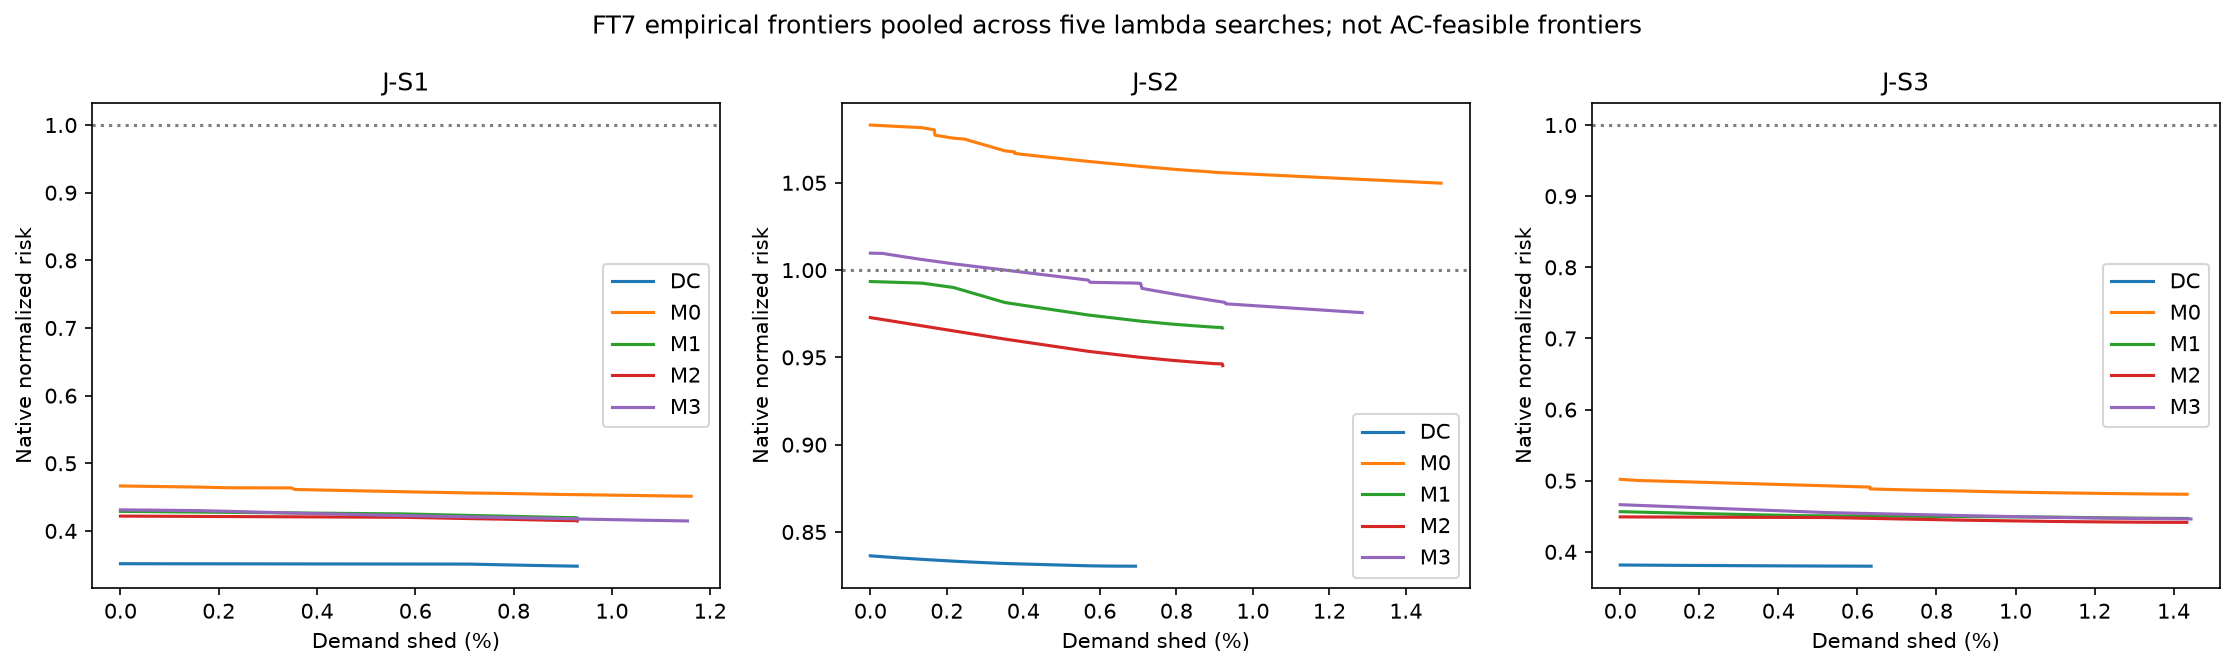

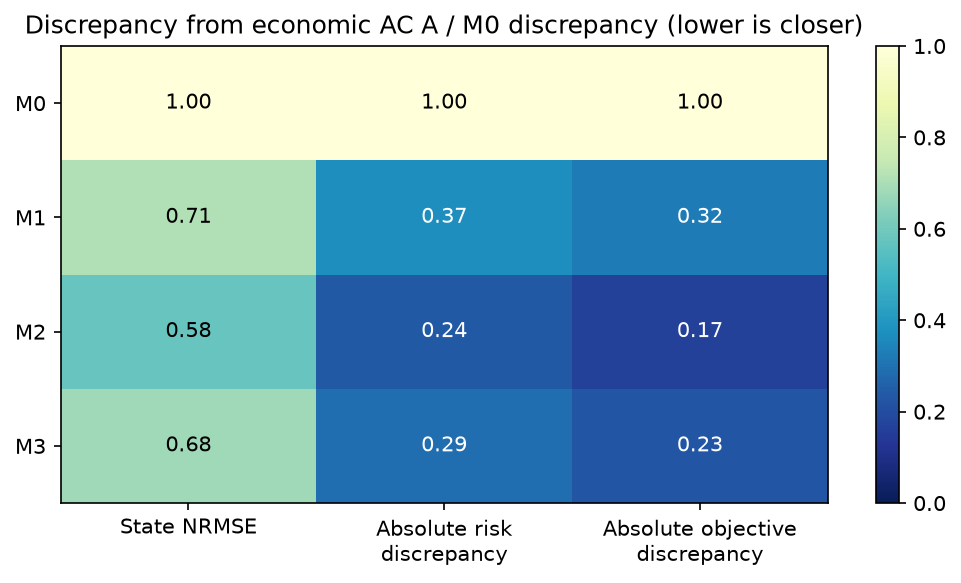

,scenario_id,method,reference_a_r_norm_ac,reference_a_l_shed_total,reference_a_j_true
3,J-S1,Guided-DC,0.393698,0.009295,0.316818
8,J-S2,Guided-DC,0.945699,0.006150,0.757789
13,J-S3,Guided-DC,0.434770,0.003568,0.348530
18,J-S1,Guided-GridSFM (released v1.1),0.393794,0.009221,0.316880
23,J-S2,Guided-GridSFM (released v1.1),0.951287,0.014920,0.764014
28,J-S3,Guided-GridSFM (released v1.1),0.445458,0.014273,0.359221
33,J-S1,Guided-GridSFM (FullTop-1000),0.393705,0.009290,0.316822
38,J-S2,Guided-GridSFM (FullTop-1000),0.945310,0.009295,0.758107
43,J-S3,Guided-GridSFM (FullTop-1000),0.447832,0.009295,0.360124
48,J-S1,Guided-GridSFM (FullTop-1500),0.393699,0.009295,0.316818


In [3]:
display(goc_comparison(ROOT).round(6))
for name in ('goc500_refined_empirical_frontiers', 'goc500_ac_agreement'):
    display(Image(filename=str(OUT / 'goc_500' / (name + '.png'))))
refs = pd.read_parquet(ROOT / 'experiments/goc_500/results/refined_study/core_results/reference_a_all.parquet')
display(refs.loc[refs.lambda_r.eq(.8), ['scenario_id', 'method', 'reference_a_r_norm_ac', 'reference_a_l_shed_total', 'reference_a_j_true']].round(6))

## GOC-500: held-out physics and runtime

FT6 held-out model diagnostics are not pooled with the selected-decision AC discrepancy. The 525 crossed warm-start solves measure IPOPT time, excluding model inference and construction. The separate RQ1 comparison uses **54 unique fixed decisions**, with repetitions summarized within each decision; its median paired evaluator speedup is about 3.59x. It measures candidate-to-state evaluation, excluding startup, downstream wildfire scoring, and publication I/O. It is not a complete OPS speedup.

,model_id,model_label,stratum,loss,cost_mape,pg_mae,qg_mae,V_mae,theta_mae,brP_mae,brQ_mae,kcl_P_resid,kcl_Q_resid,thermal_max_loading,thermal_frac_overload,feas_acc,n_graphs,runtime_seconds
0,m0,Released v1.1,fulltop,0.093298,0.008437,0.008955,0.048801,0.002298,0.020540,0.074514,0.052309,0.000666,0.001368,1.015023,0.000949,1.000000,375,69.056340
1,m0,Released v1.1,n1,0.118472,0.011977,0.011385,0.053537,0.002621,0.021122,0.076878,0.056788,0.000674,0.001471,1.018865,0.001071,0.997333,375,70.179265
2,m0,Released v1.1,combined,0.105965,0.010207,0.010168,0.051165,0.002460,0.020831,0.075696,0.054548,0.000670,0.001420,1.016944,0.001010,0.998667,750,138.396327
3,m1,FullTop-1000,fulltop,0.040794,0.007164,0.005361,0.018781,0.001484,0.009533,0.040482,0.022466,0.000263,0.000465,0.983046,0.000245,1.000000,375,67.886312
4,m1,FullTop-1000,n1,0.070146,0.008770,0.007416,0.024991,0.001883,0.010199,0.043597,0.028579,0.000292,0.000592,0.986157,0.000394,0.992000,375,70.134264
5,m1,FullTop-1000,combined,0.055547,0.007967,0.006387,0.021881,0.001684,0.009866,0.042039,0.025522,0.000278,0.000528,0.984602,0.000320,0.996000,750,138.096986
6,m2,Sequential FullTop-1500,fulltop,0.038112,0.005520,0.004706,0.018300,0.001433,0.008092,0.035024,0.020542,0.000221,0.000362,0.979472,0.000161,1.000000,375,71.161436
7,m2,Sequential FullTop-1500,n1,0.068235,0.007789,0.007088,0.024385,0.001824,0.008902,0.038692,0.026753,0.000258,0.000505,0.980635,0.000290,0.992000,375,71.192524
8,m2,Sequential FullTop-1500,combined,0.053246,0.006654,0.005895,0.021338,0.001629,0.008497,0.036857,0.023647,0.000239,0.000433,0.980054,0.000225,0.996000,750,142.338722
9,m3,FullTop-1000 + N-1-500,fulltop,0.040381,0.005228,0.005014,0.019935,0.001509,0.007606,0.036046,0.024944,0.000240,0.000484,0.988092,0.000253,1.000000,375,69.483916


<IPython.core.display.JSON object>

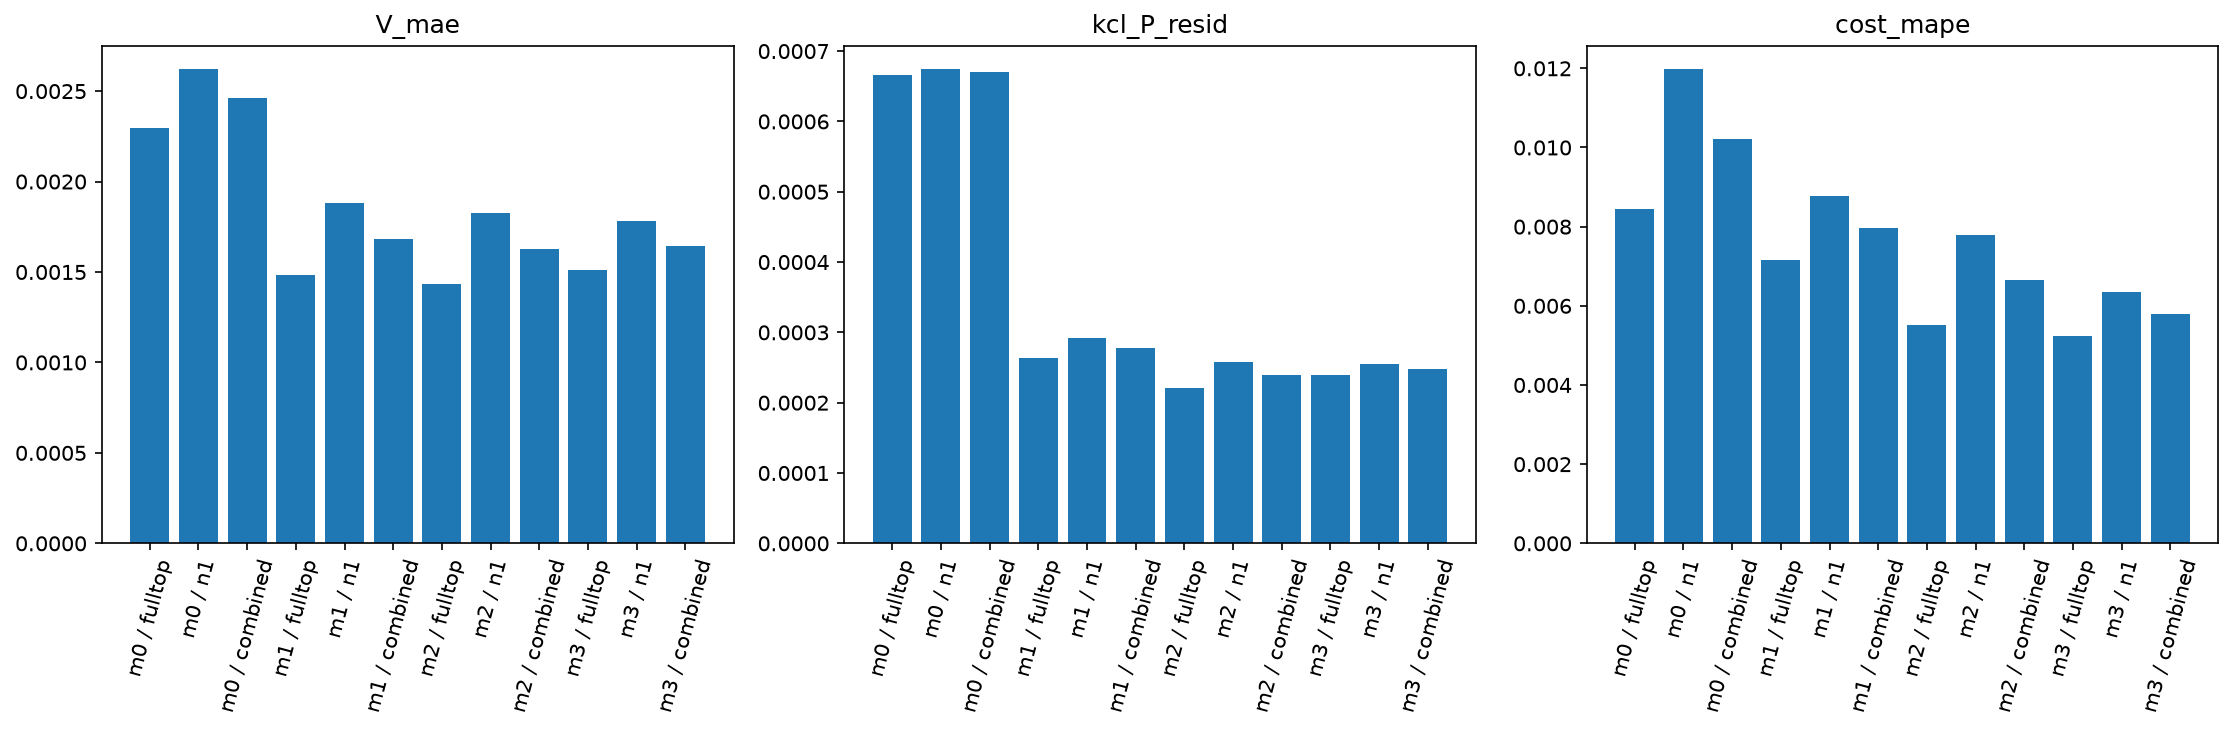

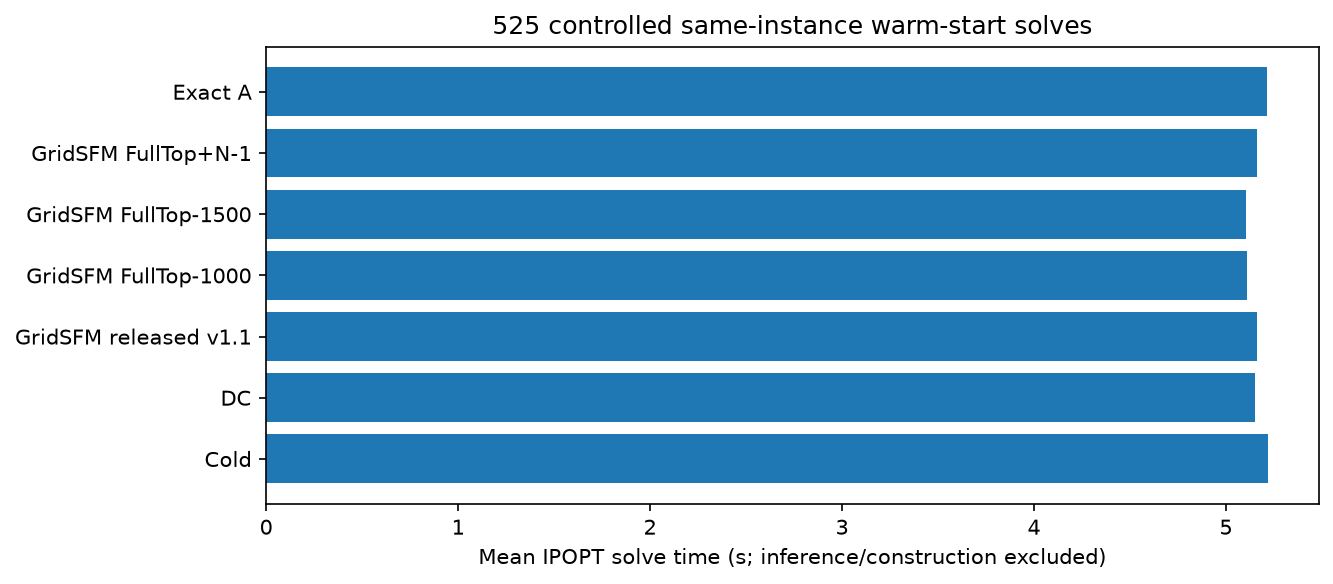

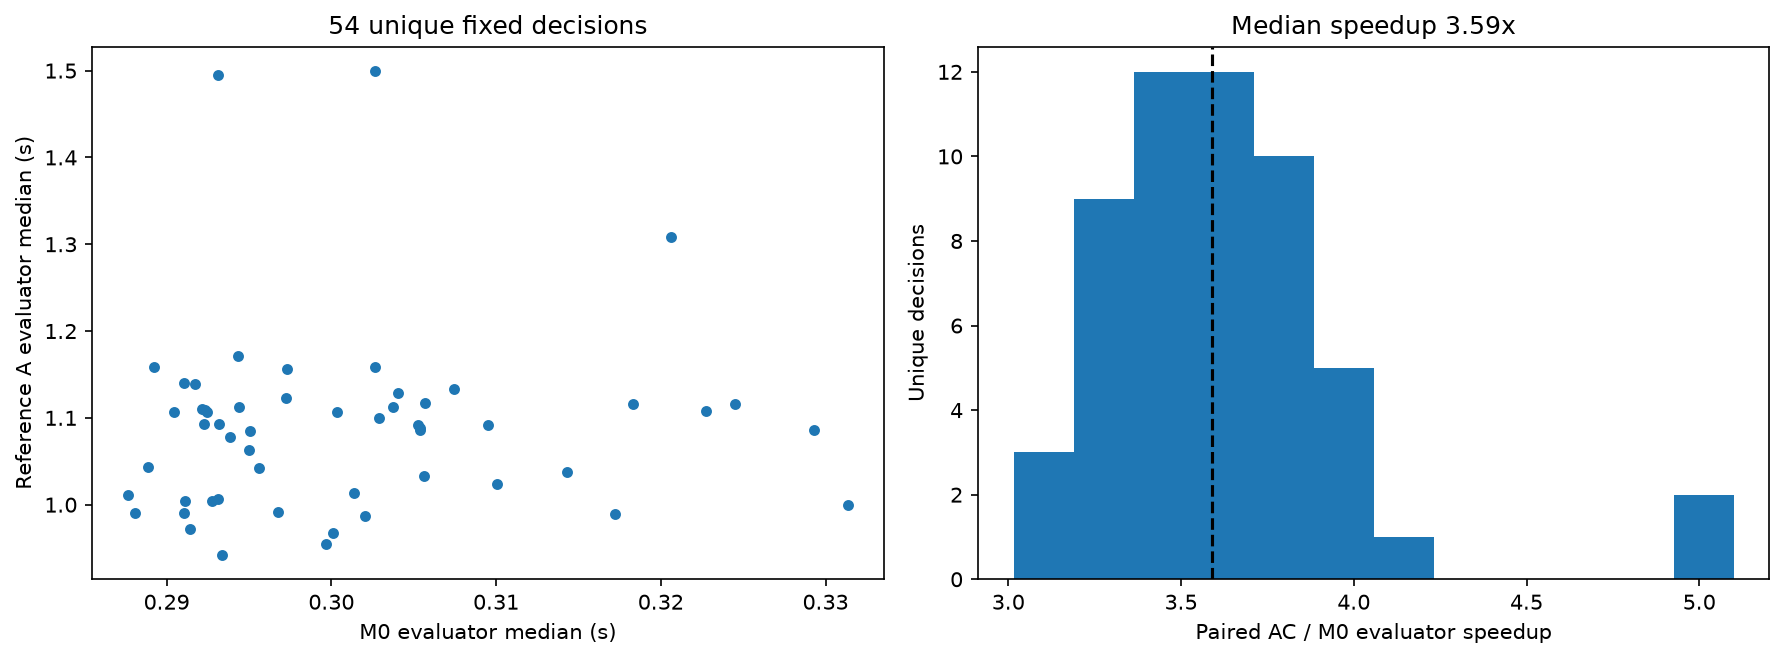

In [4]:
display(pd.read_csv(ROOT / 'experiments/goc_500/results/ft6_test_metrics.csv').round(6))
timing = json.loads((ROOT / 'experiments/goc_500/results/rq1/rq1_runtime_summary.json').read_text())
display(JSON({key: timing[key] for key in ('paired_speedup', 'statistical_unit', 'primary_boundary', 'primary_exclusions')}))
for name in ('goc500_recorded_physical_evaluation', 'goc500_warm_start', 'goc500_fixed_decision_runtime'):
    display(Image(filename=str(OUT / 'goc_500' / (name + '.png'))))

## Texas2k: predictions, candidate search, and AC audit

The local evidence includes eight certified fits, per-case physical validation for seven checkpoints, and three completed GENCO searches/audits. Native OpenGridSFM full OPS outcomes remain pending in this retained snapshot. Native G500's later remote validation status does not create missing local per-case metrics.

The search evaluates 301 topologies per completed model at lambda=0.8, with 20 continuous model calls per topology. The empirical front is within the evaluated surrogate pool; only selected finalists have AC audits. GENCO's physical evaluator and OpenGridSFM's independent physical audit are explicitly identified below.

,checkpoint_task,family,distribution,records,mean_absolute_p_mw,mean_absolute_q_mvar,mean_worst_bus_p_mw,mean_worst_bus_q_mvar,metric_source
0,v070.genco_opf.G100.s0.validation,genco_opf,G,100,84.5710,68.0406,4576.6096,7609.4697,GENCO physical evaluator
1,v070.genco_opf.G100.s0.validation,genco_opf,O,100,88.3867,68.8603,4653.6255,7609.4680,GENCO physical evaluator
2,v070.genco_opf.G100.s0.validation,genco_opf,R,100,85.4669,68.2800,4660.7580,7609.0689,GENCO physical evaluator
3,v070.genco_opf.G100_to_R400.s0.validation,genco_opf,G,100,50.6709,16.6038,9311.8529,3470.5470,GENCO physical evaluator
4,v070.genco_opf.G100_to_R400.s0.validation,genco_opf,O,100,55.7988,17.3199,9011.4442,3194.9986,GENCO physical evaluator
5,v070.genco_opf.G100_to_R400.s0.validation,genco_opf,R,100,51.5584,16.8230,9300.2767,3465.0076,GENCO physical evaluator
6,v070.genco_opf.G100_to_W400.s0.validation,genco_opf,G,100,51.9724,16.7047,9841.2927,3737.9700,GENCO physical evaluator
7,v070.genco_opf.G100_to_W400.s0.validation,genco_opf,O,100,52.3238,16.8122,9594.0497,3606.1526,GENCO physical evaluator
8,v070.genco_opf.G100_to_W400.s0.validation,genco_opf,R,100,52.7313,16.9416,9846.7643,3738.9368,GENCO physical evaluator
9,v070.genco_opf.G500.s0.validation,genco_opf,G,100,51.5638,20.5946,6264.7606,2086.6933,GENCO physical evaluator


,model,topology_key,native_r,selected_service,a_r,a_j,maximum_service_fraction,b_r
0,GENCO G100 -> R400,117;281,1.450011,0.999514,1.089042,0.871331,1.0,1.096293
1,GENCO G100 -> W400,117;281,1.511185,0.999454,1.089060,0.871357,1.0,1.096293
2,GENCO G500,117;1548,1.270111,0.997303,1.164144,0.931855,1.0,1.171874


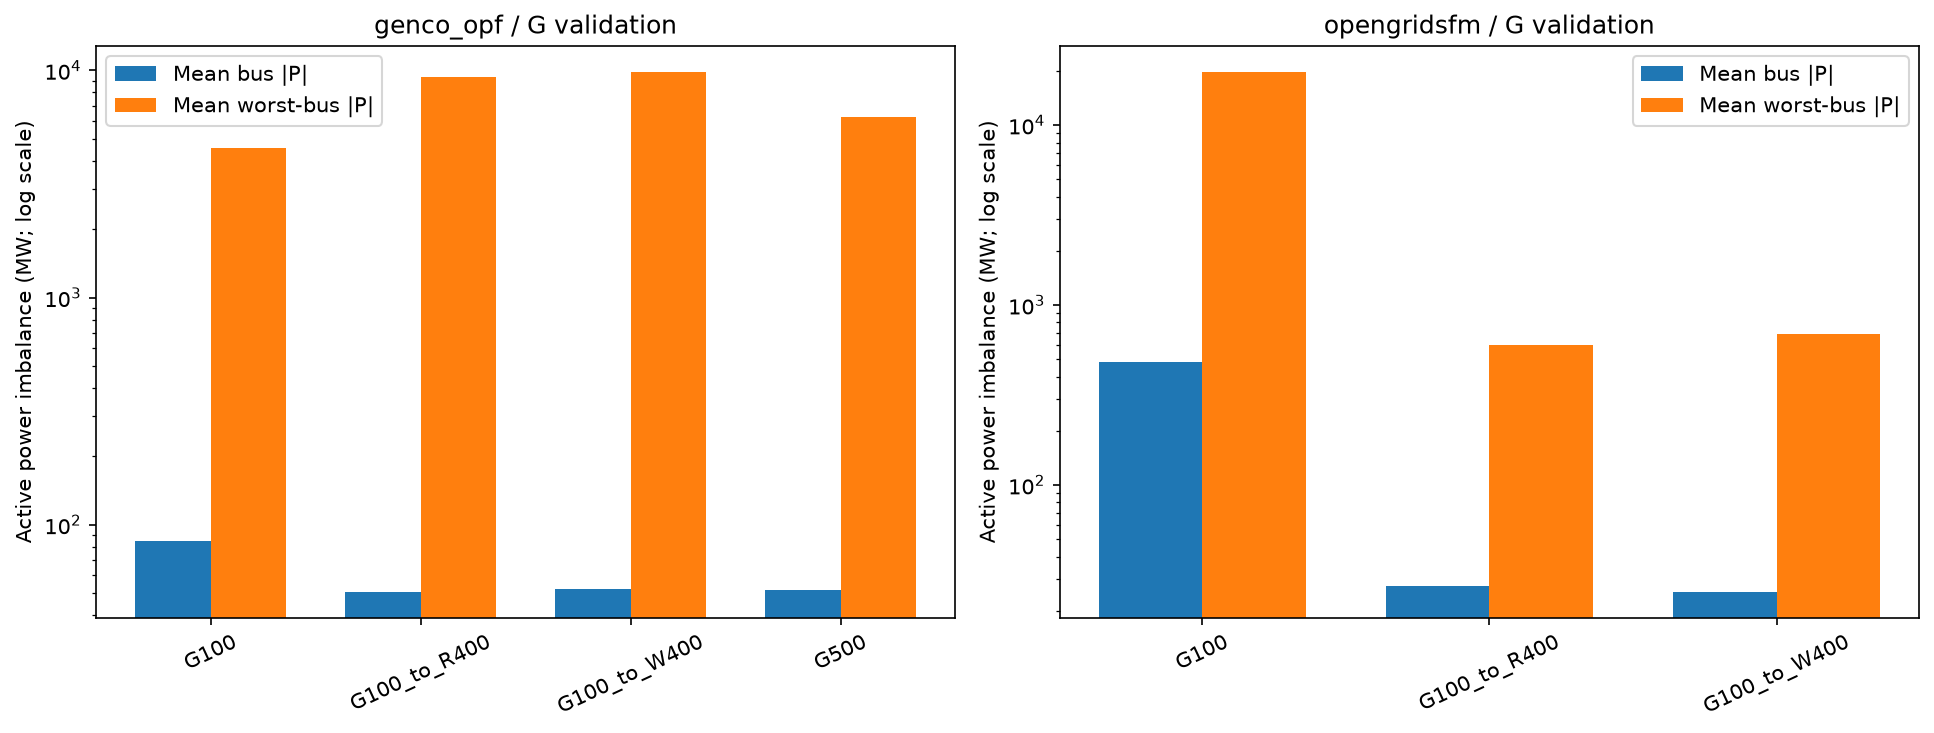

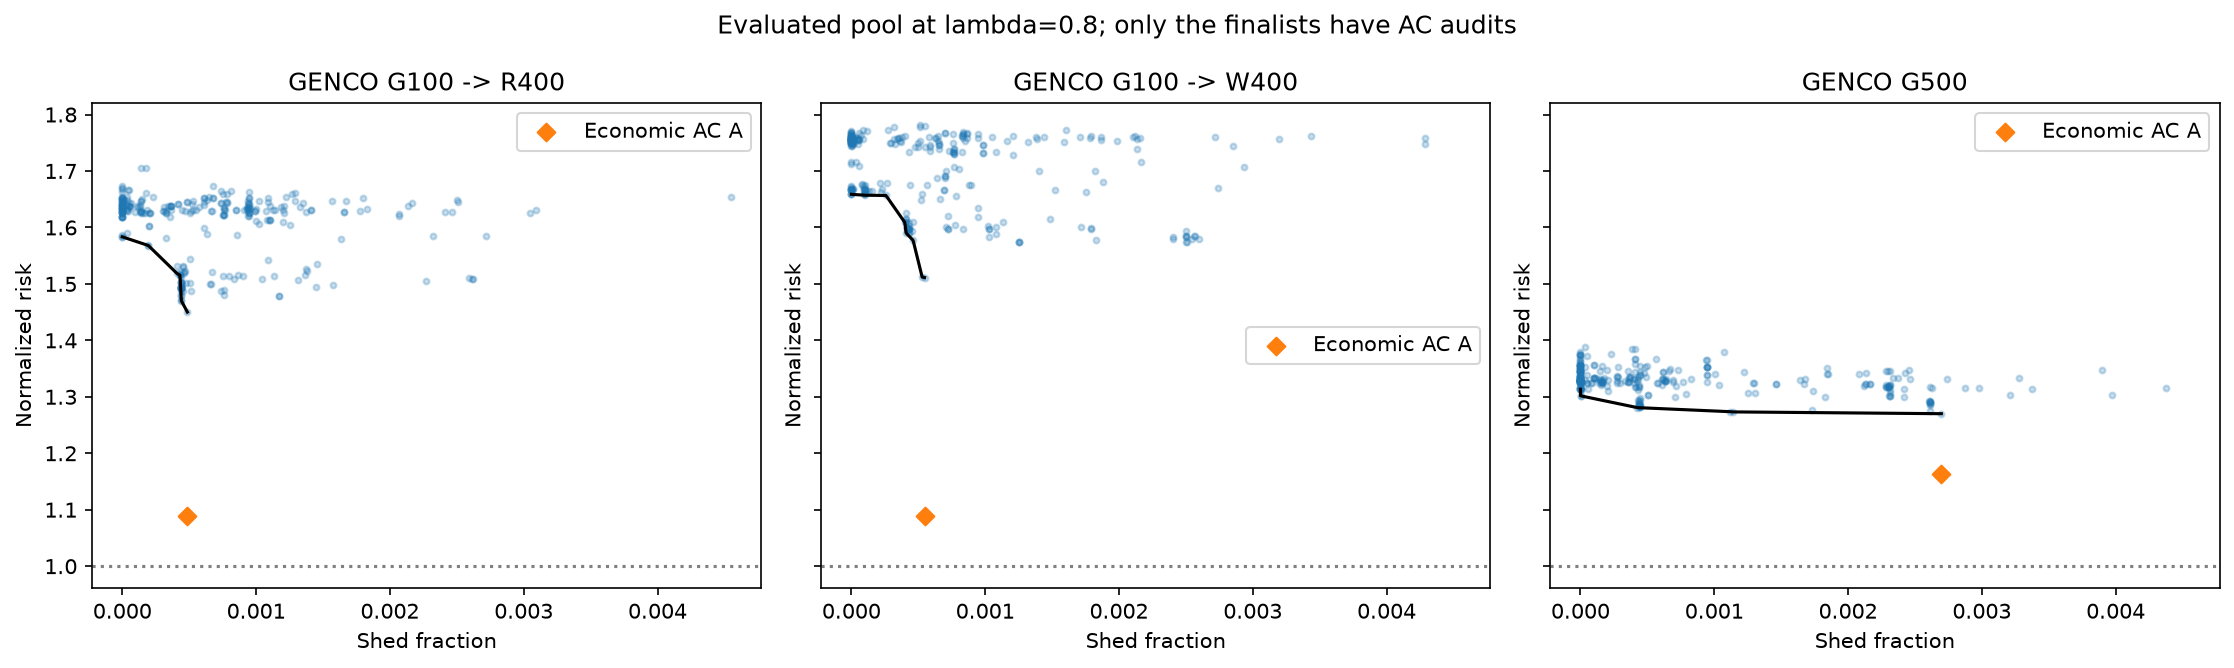

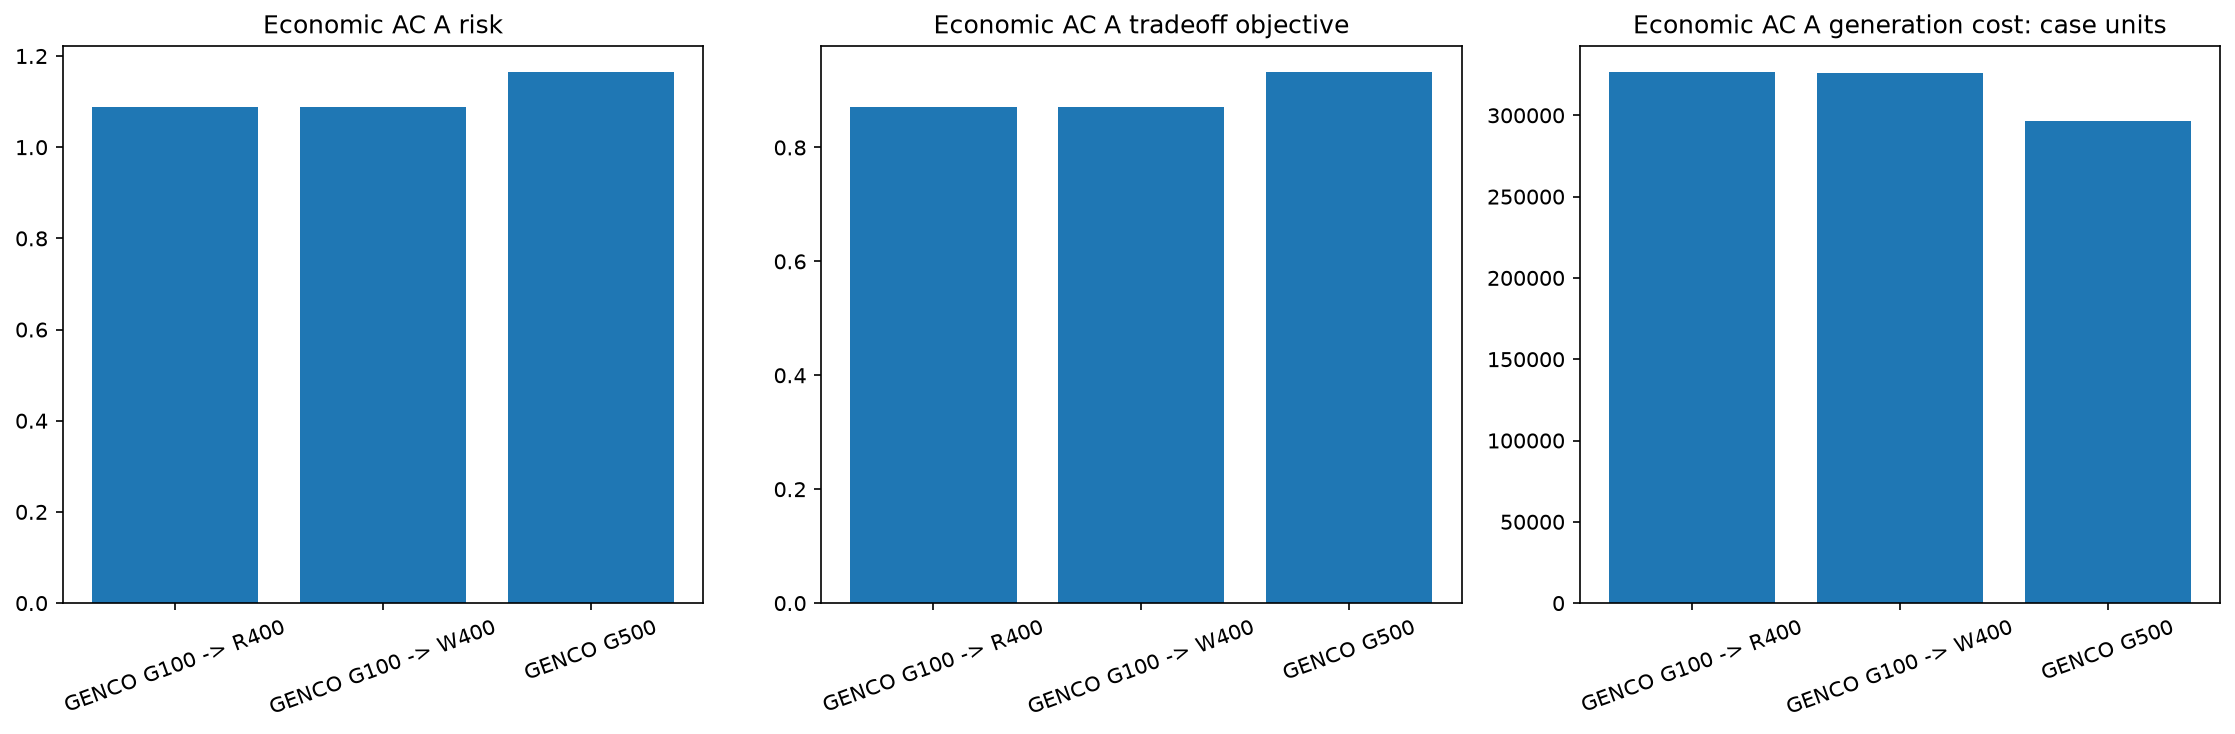

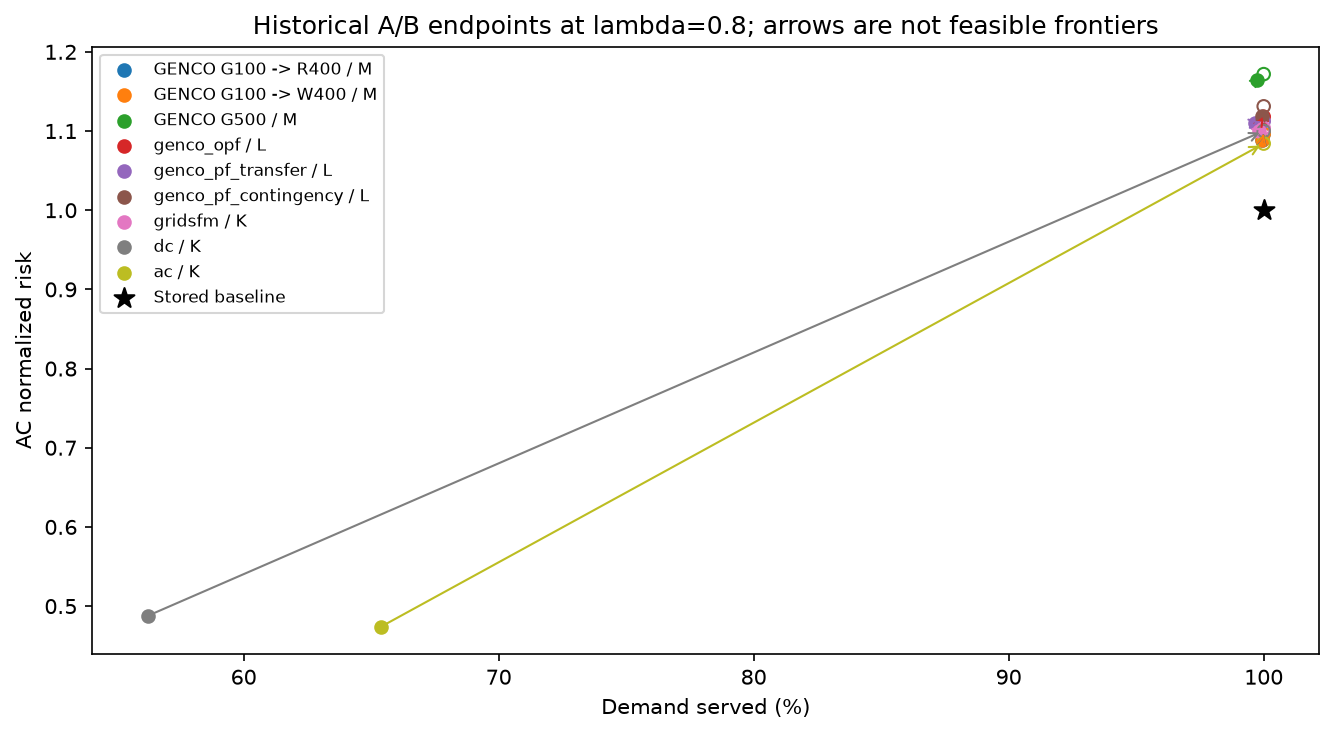

In [5]:
display(texas_validation(ROOT).round(4))
texas = ROOT / 'experiments/texas2k/results/stage_m/tables'
columns = ['model', 'topology_key', 'native_r', 'selected_service', 'a_r', 'a_j', 'maximum_service_fraction', 'b_r']
display(pd.read_csv(texas / 'finalist_native_and_exact.csv')[columns].round(6))
for name in ('physical_validation', 'empirical_tradeoffs', 'exact_reference_a', 'historical_risk_service'):
    display(Image(filename=str(OUT / 'texas2k' / (name + '.png'))))

Reference A holds selected topology and service fixed and economically redispatches with AC physics. Reference B holds topology fixed, maximizes service, then economically dispatches at that service level. The A/B arrows connect measured endpoints; they are **not feasible Pareto curves**. Historical DC/AC points have different continuous-control freedom from surrogate screening.

The three current GENCO A outcomes remain above the stored baseline risk of 1. Improved prediction diagnostics do not establish an improved risk/service decision. Recompute their objective values from retained branch/loading/service data below; this is not fresh inference or a new solve.

In [6]:
display(pd.DataFrame([recompute_retained_decision(ROOT, regime) for regime in ('G500', 'G100_to_R400', 'G100_to_W400')]).round(8))
print('Analysis regenerated from packaged evidence. Fresh predictions: 0. New AC solves: 0.')

,model,offline_branch_ids,native_r,a_r,shed,native_j,a_j,fresh_inference,fresh_ops,fresh_ac_audit
0,GENCO G500,"[117, 1548]",1.270111,1.164144,0.002697,1.016628,0.931855,False,False,False
1,GENCO G100 -> R400,"[117, 281]",1.450011,1.089042,0.000486,1.160106,0.871331,False,False,False
2,GENCO G100 -> W400,"[117, 281]",1.511185,1.089060,0.000546,1.209057,0.871357,False,False,False


Analysis regenerated from packaged evidence. Fresh predictions: 0. New AC solves: 0.
